# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 2
rng = np.random.default_rng(SEED)

expected_sha256 = {
    "data/clip-log.csv": "04f9a869dd29f868da53fc15173f7762b03343dfbd1cb16932f6e9a1464b4827",
}
for path, expected in expected_sha256.items():
    got = hashlib.sha256(Path(path).read_bytes()).hexdigest()
    assert got == expected, f"{path} does not match the hash in data/README.md"
    print("checksum ok:", path)


checksum ok: data/clip-log.csv


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


rows: 20  missing values per column:
Clip ID                       0
Session ID                    0
Source file                   0
Recorded at                   0
Clarity                       0
review_time_sec_measured      0
review_time_sec_simulated     0
Interruption sec              0
Notes                        20
Review date                   0
Reviewer                      0
dtype: int64
duplicated Clip ID: False
Interruption sec, unique values: [0]
review_time_sec_measured range: 51 - 93 s

Review time (seconds) by clarity label, all 20 clips:
                     n  mean   sd  min  max
Clarity                                    
clear                6  54.8  4.8   51   61
moderately unclear  12  76.2  7.7   60   89
very unclear         2  86.0  9.9   79   93


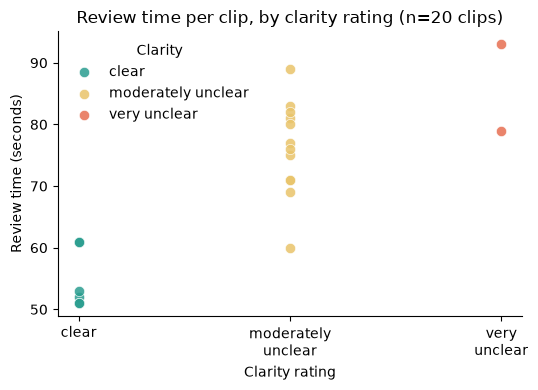

,n,mean,sd,min,max
Clarity,,,,,
clear,6,54.833333,4.833908,51,61
moderately unclear,12,76.166667,7.696910,60,89
very unclear,2,86.000000,9.899495,79,93


In [2]:
df = pd.read_csv("data/clip-log.csv")

# Data-quality pass (Part 2, step 1): missing values and timing mistakes.
print("rows:", len(df), " missing values per column:")
print(df.isna().sum())
print("duplicated Clip ID:", df["Clip ID"].duplicated().any())
print("Interruption sec, unique values:", df["Interruption sec"].unique())
print("review_time_sec_measured range:", df.review_time_sec_measured.min(), "-", df.review_time_sec_measured.max(), "s")
# No missing measurements, no duplicate clips, no interruptions logged, times all in a plausible
# 51-93 s range. The only "not collected" field is car counts (see data/README.md); the
# hypothesis in PROPOSAL.md does not need them, so that gap does not block this analysis.

order = {"clear": 1, "moderately unclear": 2, "very unclear": 3}
df["clarity_score"] = df["Clarity"].map(order)

summary = (
    df.groupby("Clarity")["review_time_sec_measured"]
    .agg(n="count", mean="mean", sd="std", min="min", max="max")
    .reindex(["clear", "moderately unclear", "very unclear"])
)
print()
print("Review time (seconds) by clarity label, all 20 clips:")
print(summary.round(1))

fig, ax = plt.subplots(figsize=(5.5, 4))
colors = {"clear": "#2a9d8f", "moderately unclear": "#e9c46a", "very unclear": "#e76f51"}
for label in ["clear", "moderately unclear", "very unclear"]:
    sub = df[df.Clarity == label]
    ax.scatter(sub.clarity_score, sub.review_time_sec_measured, color=colors[label],
               label=label, s=55, alpha=0.85, edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["clear", "moderately\nunclear", "very\nunclear"])
ax.set_xlabel("Clarity rating")
ax.set_ylabel("Review time (seconds)")
ax.set_title("Review time per clip, by clarity rating (n=20 clips)")
ax.legend(title="Clarity", frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("fig/review_time_by_clarity.png", dpi=150)
plt.show()
summary


## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [3]:
# Held-out test set: 5 clips, train on the other 15 (PROPOSAL.md: ~15 train / 5 test).
# Session S01 (C01-C02) and S02 (C03-C20) are too unbalanced (2 vs 18) to split on directly
# (decisions.md, "Sessions by a 5-minute gap"). That same entry allows a finer split in Part 2,
# as long as each simultaneous two-phone pair stays on one side:
# (C10,C11), (C12,C13), (C14,C15), (C16,C17), (C18,C19).
#
# Chosen test set, fixed by hand rather than drawn at random: {C03, C07, C16, C17, C20}.
# C16/C17 is the one paired unit sent to test, kept whole. The other four pairs, including
# the only pair that contains a "very unclear" clip (C14/C15), stay in train so that category
# is not reduced to zero training examples. The three singles (C03, C07, C20) were picked so the
# test set still has all three clarity labels represented (2 clear, 2 moderately unclear,
# 1 very unclear), rather than leaving that to chance with only 20 clips to draw from.
test_ids = ["C03", "C07", "C16", "C17", "C20"]
df["split"] = np.where(df["Clip ID"].isin(test_ids), "test", "train")

train = df[df.split == "train"].copy()
test = df[df.split == "test"].copy()

print("train:", len(train), "clips  |  test:", len(test), "clips")
print()
print("train, by clarity:\n", train.Clarity.value_counts())
print()
print("test, by clarity:\n", test.Clarity.value_counts())


train: 15 clips  |  test: 5 clips



train, by clarity:
 Clarity
moderately unclear    10
clear                  4
very unclear           1
Name: count, dtype: int64

test, by clarity:
 Clarity
moderately unclear    2
clear                 2
very unclear          1
Name: count, dtype: int64


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [4]:
# Baseline: predict the training mean review time for every clip, regardless of clarity.
baseline_pred = train.review_time_sec_measured.mean()
print(f"Baseline prediction (train mean): {baseline_pred:.2f} s, for every clip")

test_pred_baseline = np.full(len(test), baseline_pred)
mae_baseline = np.mean(np.abs(test.review_time_sec_measured.values - test_pred_baseline))
print(f"Baseline MAE on the 5 held-out clips: {mae_baseline:.2f} s")


Baseline prediction (train mean): 70.40 s, for every clip
Baseline MAE on the 5 held-out clips: 12.92 s


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


In [5]:
# Model: review_time_sec_measured = b0 + b1 * clarity_score + error
#   clarity_score: clear=1, moderately unclear=2, very unclear=3 (ordinal, one parameter
#   instead of two dummy variables, which matters with only 15 training clips).
#   b0: predicted review time at clarity_score=0 (an extrapolation; has no standalone meaning).
#   b1: predicted extra seconds per one-step increase in clarity difficulty.
#   error: assumed independent of clarity_score, roughly constant spread (checked below).
slope, intercept, r_value, p_value, se_slope = stats.linregress(
    train.clarity_score, train.review_time_sec_measured
)
print(f"fitted: review_time = {intercept:.2f} + {slope:.2f} * clarity_score")
print(f"slope standard error: {se_slope:.2f} s per clarity step  (p = {p_value:.4f}, r = {r_value:.2f})")

train_pred_model = intercept + slope * train.clarity_score
resid_train = train.review_time_sec_measured - train_pred_model
resid_sd = resid_train.std(ddof=2)  # 2 fitted parameters
print(f"residual standard deviation on training data: {resid_sd:.2f} s")

test_pred_model = intercept + slope * test.clarity_score
mae_model = np.mean(np.abs(test.review_time_sec_measured.values - test_pred_model.values))
print(f"Model MAE on the 5 held-out clips: {mae_model:.2f} s")

# Uncertainty on the two held-out MAEs: bootstrap resample the 5 test clips (with replacement),
# 20,000 times, since n=5 is too small for a normal-theory interval to mean much.
errs_baseline = np.abs(test.review_time_sec_measured.values - test_pred_baseline)
errs_model = np.abs(test.review_time_sec_measured.values - test_pred_model.values)
n_test = len(test)
boot_idx = rng.integers(0, n_test, size=(20_000, n_test))
boot_baseline = errs_baseline[boot_idx].mean(axis=1)
boot_model = errs_model[boot_idx].mean(axis=1)
boot_diff = boot_model - boot_baseline

ci_baseline = np.percentile(boot_baseline, [5, 95])
ci_model = np.percentile(boot_model, [5, 95])
ci_diff = np.percentile(boot_diff, [5, 95])

print()
print(f"MAE baseline: {mae_baseline:.2f} s   90% bootstrap interval {ci_baseline.round(2)}")
print(f"MAE model:    {mae_model:.2f} s   90% bootstrap interval {ci_model.round(2)}")
print(f"MAE(model) - MAE(baseline): {mae_model - mae_baseline:.2f} s   90% interval {ci_diff.round(2)}")
print("(a fully negative interval here means the model beat the baseline on every resample")
print(" of these same 5 clips -- it does not mean the model would do this well on new footage)")

results_table = test[["Clip ID", "Clarity", "review_time_sec_measured"]].copy()
results_table["pred_baseline"] = test_pred_baseline.round(1)
results_table["pred_model"] = test_pred_model.round(1)
results_table["abs_err_baseline"] = errs_baseline.round(1)
results_table["abs_err_model"] = errs_model.round(1)
results_table


fitted: review_time = 40.45 + 16.64 * clarity_score
slope standard error: 3.86 s per clarity step  (p = 0.0009, r = 0.77)
residual standard deviation on training data: 8.10 s
Model MAE on the 5 held-out clips: 4.93 s

MAE baseline: 12.92 s   90% bootstrap interval [ 7.16 18.6 ]
MAE model:    4.93 s   90% bootstrap interval [3.18 6.89]
MAE(model) - MAE(baseline): -7.99 s   90% interval [-13.97  -2.48]
(a fully negative interval here means the model beat the baseline on every resample
 of these same 5 clips -- it does not mean the model would do this well on new footage)


,Clip ID,Clarity,review_time_sec_measured,pred_baseline,pred_model,abs_err_baseline,abs_err_model
2,C03,moderately unclear,83,70.4,73.7,12.6,9.3
6,C07,very unclear,93,70.4,90.4,22.6,2.6
15,C16,moderately unclear,71,70.4,73.7,0.6,2.7
16,C17,clear,51,70.4,57.1,19.4,6.1
19,C20,clear,61,70.4,57.1,9.4,3.9


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


In [6]:
# Simulate data from the fitted model (same training clarity scores, known b0, b1, resid_sd),
# refit many times, and check that the fitting procedure recovers the parameters it was given.
n_sims = 2000
x_train = train.clarity_score.values
sim_slopes = np.empty(n_sims)
sim_intercepts = np.empty(n_sims)

for i in range(n_sims):
    y_sim = intercept + slope * x_train + rng.normal(0, resid_sd, size=len(x_train))
    s, b, _, _, _ = stats.linregress(x_train, y_sim)
    sim_slopes[i] = s
    sim_intercepts[i] = b

print(f"true slope {slope:.2f}      recovered mean {sim_slopes.mean():.2f}, sd {sim_slopes.std():.2f}")
print(f"true intercept {intercept:.2f}  recovered mean {sim_intercepts.mean():.2f}, sd {sim_intercepts.std():.2f}")
print("The simulated-and-refit slope and intercept land right on the values used to simulate")
print("them, so the fitting code is not the source of error here -- the 15-clip training set is.")


true slope 16.64      recovered mean 16.68, sd 3.81
true intercept 40.45  recovered mean 40.33, sd 7.16
The simulated-and-refit slope and intercept land right on the values used to simulate
them, so the fitting code is not the source of error here -- the 15-clip training set is.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


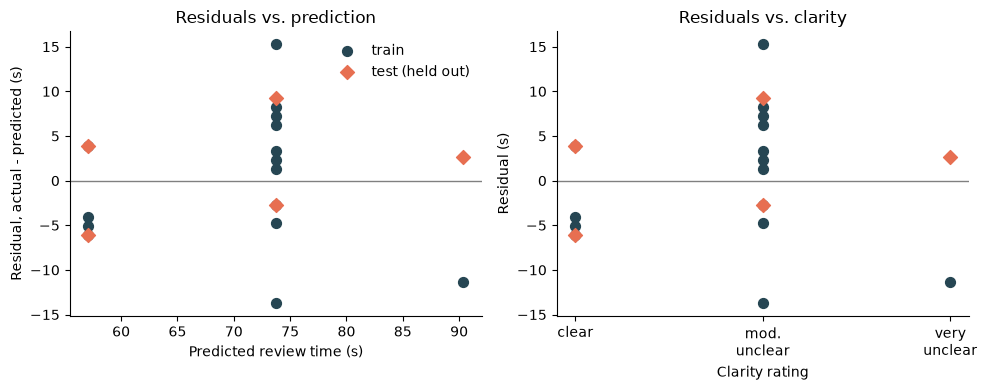

Training residuals look like noise scattered around 0 at every clarity level, with no
obvious curve or fan shape -- consistent with the straight-line, constant-spread model.
The spread is similar across the three clarity groups (no strong fan pattern), so a single
residual standard deviation for all three groups is a reasonable simplification here,
though with only 1 training clip in the 'very unclear' group that check is weak for that
group specifically. The held-out (diamond) points sit inside the training scatter, not
systematically above or below it.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].axhline(0, color="grey", linewidth=1, zorder=1)
axes[0].scatter(train_pred_model, resid_train, color="#264653", s=50, zorder=3, label="train")
axes[0].scatter(test_pred_model, test.review_time_sec_measured.values - test_pred_model.values,
                color="#e76f51", s=50, zorder=3, marker="D", label="test (held out)")
axes[0].set_xlabel("Predicted review time (s)")
axes[0].set_ylabel("Residual, actual - predicted (s)")
axes[0].set_title("Residuals vs. prediction")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].axhline(0, color="grey", linewidth=1, zorder=1)
axes[1].scatter(train.clarity_score, resid_train, color="#264653", s=50, zorder=3)
axes[1].scatter(test.clarity_score, test.review_time_sec_measured.values - test_pred_model.values,
                color="#e76f51", s=50, zorder=3, marker="D")
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(["clear", "mod.\nunclear", "very\nunclear"])
axes[1].set_xlabel("Clarity rating")
axes[1].set_ylabel("Residual (s)")
axes[1].set_title("Residuals vs. clarity")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("fig/residuals.png", dpi=150)
plt.show()

print("Training residuals look like noise scattered around 0 at every clarity level, with no")
print("obvious curve or fan shape -- consistent with the straight-line, constant-spread model.")
print("The spread is similar across the three clarity groups (no strong fan pattern), so a single")
print("residual standard deviation for all three groups is a reasonable simplification here,")
print("though with only 1 training clip in the 'very unclear' group that check is weak for that")
print("group specifically. The held-out (diamond) points sit inside the training scatter, not")
print("systematically above or below it.")


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


**Limits from the modeling side of this project** (Part 2). The business-decision limits
(staffing/cost assumptions) are in `presentation.qmd` / the business teammate's section.

- **The clarity labels are not independent evidence.** Per `decisions.md` ("Clarity rated after
  timing"), clarity was rated *after* review time was measured and after the rater had already
  seen a preliminary, AI-generated clarity rating -- and the final ratings matched the AI's on
  all 20 clips. The protocol (`protocol/review-protocol.md`) calls for rating clarity *before*
  timing, specifically to avoid this. This is the single assumption to trust least in this
  analysis: if a slow clip was more likely to be labeled "unclear" after the fact, the
  clarity-time relationship in this dataset is inflated relative to what a blind rating would
  show, and the strong test-set result above should be read with that in mind.
- **One reviewer, one evening, one scene type.** All timing was done by one person, in clip-ID
  order, on footage from a single evening at retail parking lots in dusk/night lighting. Practice
  effects, this particular reviewer's speed, and this lighting condition are all baked into both
  the baseline and the model; neither is shown to generalize to another reviewer, daylight, or
  other scene types.
- **n=15 training clips, and only 1 of them is "very unclear."** The regression's estimate for
  the "very unclear" category is effectively set by a single clip (C14). The slope's standard
  error (reported with the model fit above) reflects this, but a coefficient resting on one
  observation should not be trusted as precisely as the point estimate suggests.
- **The 90% bootstrap intervals above describe these same 5 held-out clips**, resampled with
  replacement -- they are not a claim about a new, unseen batch of footage. With 5 test clips,
  a different random holdout could plausibly reorder which method wins, even though in this
  particular split the model's advantage is large relative to the gap between the two methods.
- **What more data or time would fix first:** a second, blind clarity rating (planned in
  `decisions.md`, not yet done) to check whether the clarity-time link survives being rated
  before timing; more "very unclear" clips, since that is the thinnest category; and footage
  from more than one evening/reviewer before trusting this for staffing decisions beyond this
  exact setting.
